# 04 — Staged settlement_value research

This notebook takes you from **model assumptions** to **small, deliberate entry experiments**, and then to **exploring the saved results**, all in one place.

It reuses existing parts and adds no new simulation code:

* the real `settlement_value` strategy and the closed-loop replay;
* the batch runner (`batch.run_batch`), which handles progress, resume and the Windows worker processes;
* the results explorer from notebook 03.

**Run All is safe.** Every cell that would launch simulations is *disarmed*: it prints what it would do and stops. A stage runs only when you set its `RUN_STAGE_…` flag to `True` and run that cell. Editing a setting never launches anything.

**Default plan** (counts are calculated below from your actual choices):

| Stage | What | Scenario | Default size |
|---|---|---|---|
| A | six TWAP configurations (3 edges × 2 entry times) | friction | 6 × 45 windows = 270 runs |
| B | one Endpoint benchmark on the same windows | friction | 45 runs |
| C | 0–2 TWAP finalists you choose by hand, changing only the scenario | favorable | up to 90 runs |

The holdout windows are never used here.

## 1. Vocabulary and what is being measured

**Terms**

* **Configuration:** one complete set of strategy settings. Examples are the model backend, the minimum edge, the entry timing and the budget. Two configurations differ in at least one setting.
* **Scenario:** a named set of *execution assumptions*: delays, worse prices and available depth. `friction` is cautious. `favorable` is generous, and it is **not** an upper bound on profit.
* **Window:** one recorded 5-minute BTC up/down market.
* **Run:** one configuration replayed on one window under one scenario.

  Six configurations × 45 windows × 1 scenario = 270 runs. That is still **six configurations tried on one market history**, not 270 independent experiments.

**The data**

* **Recorded feeds:** each window replays the recorded Binance BTCUSDT trades (the model's spot input), the PolyBolt TWAP reference feed (the settlement reference series) and the Polymarket order books.
* **Proxy outcomes:** the outcome of each window is a **proxy label**, taken from the recorded payout vector. It is not a qualified settlement.
* **Provisional K:** the opening threshold K is sealed from the replayed feed without attestation, so it is **PROVISIONAL**.

**Three different qualities.** Keep them apart:

1. **Probability quality:** are the model's probabilities well calibrated against outcomes? This is judged *without trading*, with Brier score and log loss on common rows. See notebook **02** and `analysis.probability_quality`.
2. **Entry quality:** given those probabilities, does the entry rule pick good trades? This is the job of the minimum edge and the entry timing, and it is what stage A varies.
3. **Execution quality:** what happens between the decision and the fill: delays, adverse ticks and partial depth. This is fixed by the scenario, and stage C changes only this.

A configuration can lose money because the probabilities are poor, because the entry rule is poor, or because execution was costly. Trading P&L alone cannot tell you which.

**Why vary so little?** Each extra axis multiplies the runs *and* the chances of finding a setting that looked good by luck. With ~45 windows and a handful of fills per configuration, only a small search can be read. The model, the volatility, the budget and the execution settings stay **fixed**. Only the entry edge and the entry timing vary.

**Choosing settings is not launching.** Sections 2–6 only *describe* an experiment. Section 7 shows the workload. Simulations start only from an armed run cell.

In [1]:
# Use source from this checkout, even when the interpreter is shared.
import sys
from pathlib import Path
_cwd = Path.cwd().resolve()
_repo_root = next(p for p in (_cwd, *_cwd.parents)
                  if (p / 'src/tyrex_pm').is_dir())
sys.path.insert(0, str(_repo_root / 'src'))

# Reload edited project code (explorer, timelines, staged...) before each cell runs,
# so code changes apply without restarting the kernel.
%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import HTML, display

from tyrex_pm.research.strategy_lab import explorer as ex
from tyrex_pm.research.strategy_lab import staged as st

pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 90)

## 2. Data and window selection

The **development/holdout split** is read from the frozen file `var/research/strategy_runs/s2/split/split.json`. It is never recomputed here: recomputing it on a larger inventory would move the chronological boundary into the holdout.

Each window is labelled with one of three roles:

* `development` windows are the only ones an experiment can use;
* `holdout (excluded)` windows are kept for a single final evaluation of a shortlist fixed in advance;
* `not in frozen split (excluded)` windows were recorded after the split and are left untouched.

**Known limitations of this data:**

* proxy outcome labels and a PROVISIONAL K;
* the reference is the PolyBolt TWAP feed, not the live RTDS stream;
* the averaging window and tie rule are assumed, not verified;
* a collector-clock gap removes some evaluations (`future_binance_rejected`), so some possible entries are missing from every run;
* feed gaps inside a window show up as invalid books and recorded limitations.

In [2]:
windows = st.window_table()          # current inventory, labelled by the frozen split
display(st.collections_summary(windows))
print(windows['role'].value_counts().to_string())

role
development                       94
holdout (excluded)                39
not in frozen split (excluded)     2


,collection,role,windows,first,last
0,2dd3d0d125dc4a9fb5e50daf3f9bfd3e,development,7,2026-10-01 15:35:00+00:00,2026-10-01 16:05:00+00:00
1,380e44875c8e483aa4f76e17cab06c02,development,38,2026-10-06 14:45:00+00:00,2026-10-06 17:50:00+00:00
2,380e44875c8e483aa4f76e17cab06c02,holdout (excluded),18,2026-10-06 17:55:00+00:00,2026-10-06 19:20:00+00:00
3,380e44875c8e483aa4f76e17cab06c02,not in frozen split (excluded),2,2026-10-06 19:25:00+00:00,2026-10-06 19:30:00+00:00
4,58a756de83c8403983a25c5609b995f1,development,49,2026-10-15 14:50:00+00:00,2026-10-15 18:50:00+00:00
5,58a756de83c8403983a25c5609b995f1,holdout (excluded),21,2026-10-15 18:55:00+00:00,2026-10-15 20:35:00+00:00


**Select windows.**

* `COLLECTIONS = None` uses all recorded collections. Otherwise give a list of collection ids from the table above.
* `SMOKE_WINDOWS = None` uses every selected development window. A small number, such as `1` or `2`, makes a clearly labelled **smoke** experiment for checking the pipeline. Its results are kept in a separate directory (`smoke-…`) and must not be read as evidence.

The window identities are **frozen** into the experiment when its first stage is launched. A later recording does not change that experiment's membership. A different selection creates a different experiment.

In [3]:
COLLECTIONS = None          # e.g. ['380e44875c8e483aa4f76e17cab06c02']
SMOKE_WINDOWS = None        # e.g. 1 for a smoke experiment

selected = st.select_windows(windows, collections=COLLECTIONS, smoke_windows=SMOKE_WINDOWS)
KIND = 'smoke' if SMOKE_WINDOWS else 'full_development'
print(f'{len(selected)} development windows selected ({KIND}); '
      f"{(windows['role'] != 'development').sum()} holdout/unsplit windows excluded")
if len(selected):
    print('from', selected['window_utc'].min(), 'to', selected['window_utc'].max(),
          'across', selected['collection'].nunique(), 'collection(s)')

94 development windows selected (full_development); 41 holdout/unsplit windows excluded
from 2026-10-01 15:35:00+00:00 to 2026-10-15 18:50:00+00:00 across 3 collection(s)


## 3. Model baseline (fixed for the whole experiment)

These settings shape the **probability** the strategy computes. They are the same for every configuration in every stage. Edit them before the first launch. An edited baseline is a different experiment (a new id), so earlier results are never reused by mistake.

**Backends**

* `PRIMARY_BACKEND = 'twap_proxy_diffusion'` (**TWAP proxy**) models the settlement as an *average* over the last seconds. On common rows its probabilities matched the book's quality (notebook 02; corrected comparison).
* `BENCHMARK_BACKEND = 'endpoint_diffusion'` (**Endpoint**) models only the closing price. It is kept as a benchmark, because it was clearly worse in probability quality.

**Volatility** (EWMA on Binance 1-second log returns)

* `half_life_s` sets how quickly the estimate forgets old returns.
* `sigma_floor` is the lowest volatility allowed. The old 1e-4 floor bound every estimate.
* `sigma_scale` multiplies the estimate before pricing.

**Uncertainty bands** (they make the *conservative* probability)

* `sigma_band` widens or narrows volatility by ±band.
* `reference_band_bps` shifts the spot by ± that many basis points.

The strategy only buys when the *conservative* edge clears the cost.

**Spot input**

* `spot_input = 'binance_spot'` uses the raw Binance price.
* `'aligned_reference'` maps Binance into the reference's level, which also absorbs the TWAP lag.

**Evidence-labelled settings are not knobs.** These keep their provenance labels, are shown below and **cannot** be edited in this notebook:

* the averaging length (60 s, ASSUMED);
* the reference series identity (ASSUMED);
* the tie rule (`AT_OR_ABOVE_K`, ASSUMED);
* fees (SCENARIO_ASSUMPTION_NOT_VERIFIED);
* the K quality (PROVISIONAL accepted for research);
* payout semantics (proxy outcome, unit UNKNOWN).

Adjusting them until P&L improves would be fitting assumptions to noise.

**Judging the model.** Assess probability quality separately, *before* reading P&L: run notebook 02's Brier/log-loss comparison against the book on the same windows. A configuration that makes money with a poorly calibrated model is most likely lucky.

In [4]:
PRIMARY_BACKEND = 'twap_proxy_diffusion'
BENCHMARK_BACKEND = 'endpoint_diffusion'
MODEL = {'sigma_band': 0.25, 'reference_band_bps': 1.0, 'spot_input': 'binance_spot'}
VOLATILITY = {'half_life_s': 30.0, 'sigma_floor': 1e-5, 'sigma_scale': 1.0}

## 4. Budget (fixed)

* `max_debit_usdc` is the most the strategy may *plan* to spend on one window.
* `max_loss_usdc` is the most it may plan to lose. For a bought binary option the loss equals the spending.

The research seed is **5 USDC** for both.

**Spending more changes dollar P&L, not the signal.** Doubling the budget roughly doubles wins *and* losses, and it can change which orders fill against the available depth. It does not make the model's probabilities any better. Keep the budget fixed across the comparison.

The budget is a *planning* limit. The size is chosen at the prices seen while walking the book. Adverse ticks and the limit buffer can make the fill cost slightly more, and a 5-share minimum at a very low price can force a larger order. **The explorer counts every fill that spent above the cap** instead of hiding it.

In [5]:
SIZING = {'max_debit_usdc': '5', 'max_loss_usdc': '5'}

## 5. Execution assumptions (fixed)

The named scenario files in `config/research/scenarios/` are used unchanged:

* **Primary scenario: `friction`.** Stages A and B use it.
* **Finalist scenario: `favorable`.** Stage C runs a finalist again under it to see how much execution alone moves the result.

The table shows their effective values:

* **information delay:** recorded data → strategy view;
* **order delay:** submission → venue;
* **feedback delay:** venue result → strategy;
* **adverse ticks:** each fill is this many ticks worse;
* **participation:** the share of displayed depth available;
* **fees:** the assumed fee curve, labelled *not verified*.

**`LIMIT_BUFFER_TICKS`** lets the order limit sit one tick above the worst walked level. That leaves room for the book to move before the order arrives, without ever paying beyond the limit. Without it, `friction`'s adverse tick left most taker orders unfilled.

**Execution sensitivity is deferred.** Do not tune delays or fees to improve results.

In [6]:
PRIMARY_SCENARIO = 'friction'
FINALIST_SCENARIO = 'favorable'
LIMIT_BUFFER_TICKS = 1
display(st.scenario_table(PRIMARY_SCENARIO, FINALIST_SCENARIO))

,friction,favorable
information delay [ms],100,0
decision delay [ms],0,0
order delay [ms],300,0
feedback delay [ms],300,0
adverse ticks per fill,1,0
share of displayed depth available,0.25,1
maker fills,no_fill,no_fill
data-gap policy,invalidate_path,invalidate_path
event tie policy,observations_before_actions,observations_before_actions
fee rate · exponent · unit,0.07 · 1 · shares,0.07 · 1 · shares


## 6. Entry search (the only thing stage A varies)

**Search axes**

* `EDGES` (`entry.min_edge_per_share`, USDC per share): the minimum *conservative* edge (model value minus price and fee) needed to buy. Higher edges trade less often.
* `TAUS` (`entry.tau_max_s`, seconds): the earliest entry, measured as seconds remaining before the window closes. `240` allows entry from 4 minutes before close, and `150` waits until 2.5 minutes before close.

**Fixed entry restrictions (`ENTRY_FIXED`)**

* `tau_min_s`: no entry later than this many seconds before close (the cutoff).
* `max_entry_price`: never pay more per share than this.
* `target_mode = 'cap_only'`: buy as much as the budget and the edge allow.
* `target_profit_usdc`: used only by `require_target`. It is an *expected-profit* threshold for the intended purchase. It is **not** a take-profit order and **not** a guaranteed gain. Positions are held to resolution.

**Stage B benchmark.** The benchmark uses the Endpoint backend with the edge and entry timing you choose here. Every other setting matches the TWAP baseline.

In [7]:
EDGES = ['0.02', '0.05', '0.08']
TAUS = [240.0, 150.0]
ENTRY_FIXED = {'tau_min_s': 30.0, 'max_entry_price': '0.97', 'target_mode': 'cap_only',
               'target_profit_usdc': '3'}
BENCHMARK_EDGE = '0.05'
BENCHMARK_TAU = 240.0

### Assemble and validate the design

The project's own configuration validation runs on every generated configuration, so an invalid value fails here, before anything is launched.

* The first table lists every configuration with a readable label and its key settings.
* The second table shows the evidence-labelled settings with their provenance.
* Set `SHOW_FULL_SETTINGS = True` to print the complete effective settings of one configuration, inherited defaults included.

In [8]:
design = st.Design(
    baseline={'model': MODEL, 'volatility': VOLATILITY,
              'entry': {**ENTRY_FIXED, 'limit_buffer_ticks': LIMIT_BUFFER_TICKS},
              'sizing': SIZING},
    primary_backend=PRIMARY_BACKEND, benchmark_backend=BENCHMARK_BACKEND,
    edges=tuple(EDGES), taus=tuple(TAUS),
    benchmark_edge=BENCHMARK_EDGE, benchmark_tau=BENCHMARK_TAU,
    primary_scenario=PRIMARY_SCENARIO, finalist_scenario=FINALIST_SCENARIO,
)
design.validate()
generated = st.describe_configs(design.stage_parameters('A') + design.stage_parameters('B'))
generated.insert(0, 'stage', ['A'] * (len(generated) - 1) + ['B'])
display(generated.drop(columns='config_id'))
print(len(generated) - 1, 'stage A configurations,', 1, 'stage B benchmark')

effective = st.flat(st.effective_parameters(design.stage_parameters('A')[0]))
display(effective[effective['provenance'] != ''])

SHOW_FULL_SETTINGS = False
if SHOW_FULL_SETTINGS:
    display(effective)

6 stage A configurations, 1 stage B benchmark


,stage,label,backend,min_edge_per_share,tau_max_s,tau_min_s,limit_buffer_ticks,max_debit_usdc
0,A,TWAP | edge 2¢ | entry from 240s remaining,twap_proxy_diffusion,0.02,240.0,30.0,1,5
1,A,TWAP | edge 2¢ | entry from 150s remaining,twap_proxy_diffusion,0.02,150.0,30.0,1,5
2,A,TWAP | edge 5¢ | entry from 240s remaining,twap_proxy_diffusion,0.05,240.0,30.0,1,5
3,A,TWAP | edge 5¢ | entry from 150s remaining,twap_proxy_diffusion,0.05,150.0,30.0,1,5
4,A,TWAP | edge 8¢ | entry from 240s remaining,twap_proxy_diffusion,0.08,240.0,30.0,1,5
5,A,TWAP | edge 8¢ | entry from 150s remaining,twap_proxy_diffusion,0.08,150.0,30.0,1,5
6,B,Endpoint | edge 5¢ | entry from 240s remaining,endpoint_diffusion,0.05,240.0,30.0,1,5


,value,provenance
setting,,
settlement.comparison,AT_OR_ABOVE_K,ASSUMED tie rule: UP wins at or above K
settlement.reference_series,chainlink:btcusd:twap:60,"ASSUMED: replayed PolyBolt TWAP feed, not the live RTDS stream"
settlement.provenance_status,ASSUMED,ASSUMED (not VERIFIED)
model.averaging_window_s,60.0,ASSUMED from provider metadata twapLookbackSeconds = 60; boundary and weights unverified
quality.accepted_k_qualities,"[""CONFIRMED_CANONICAL"", ""PROVISIONAL""]",K replayed without attestation is PROVISIONAL; research runs accept it explicitly
fees.rate,0.07,SCENARIO_ASSUMPTION_NOT_VERIFIED
fees.exponent,1,SCENARIO_ASSUMPTION_NOT_VERIFIED


## 7. The experiment and its stages

The experiment id is derived from the design, the selected windows and the kind (`full_development` or `smoke`). Rerunning this notebook with the same settings therefore **reopens the same experiment** and can resume it. Changing any setting gives a new id, so the old results are never mixed in.

Nothing is written until a stage is launched. Results go to `var/research/strategy_runs/staged/<experiment-id>/`. The older `s2/grid` and `s2/validation_seed` bundles are untouched.

**What is saved:**

* `experiment.json`: the design, the frozen window identities, the split file's hash, the data cache keys of every window and the code identity;
* `stage_X/stage.json`: every configuration with its **full effective settings**, the effective scenario, a fingerprint of all inputs, the status and every attempt (including interruptions and failures);
* `stage_X/parts/`: one file per finished window;
* `stage_X/summaries.parquet` and `stage_X/manifest.json`: the batch runner's results and manifest.

**Running, interrupting and resuming.** Each stage has a preview cell and a separate, disarmed run cell.

* **To run:** set `RUN_STAGE_X = True` and run that cell. Progress prints once per finished window.
* **To interrupt:** use the kernel's *Interrupt* button. Queued windows are cancelled. Windows already running finish and are saved, which can take a few minutes. The stage is then recorded as `interrupted`.
* **To resume:** run the same cell again with the same settings. Finished windows are reused from `parts/`.
* **Refusals:**
  * if the configurations, scenario, windows or recorded data differ, the stage refuses to resume;
  * if the strategy or replay source code changed, it also refuses, unless you pass `allow_code_change=True`. That choice is recorded.

**Workers.**

* Each worker holds about 2.5 GB of memory, and 4 workers suit a 32 GB machine.
* `WORKERS = 1` runs inside the kernel.
* Higher values start separate processes via the batch runner, which is safe on Windows.

**Timelines (optional).** `KEEP_TIMELINES = True` makes a *new* stage also save its per-second series in `stage_X/decisions.parquet`: model probabilities, book quotes, actions and reasons. The explorer's probability-vs-book chart (section 8) then reads it directly. Every run's order and fill events are saved in its summary row either way, and they are small. Full timelines add roughly 600 rows per run.

The choice is fixed when a stage starts, because its part files depend on it. A resume uses the recorded value, and a completed stage is never rerun to add timelines. For a stage saved without them, generate single runs from the explorer instead.

In [9]:
exp = st.create_or_open(design, selected, kind=KIND, write=False)   # writes nothing yet
WORKERS = 4
KEEP_TIMELINES = True    # new stages also save per-second timelines (see above)
print('experiment:', exp.id, '(already on disk)' if exp.saved else '(not yet launched)')
print('directory: ', exp.path)

experiment: full_development-7f132d3ee2 (already on disk)
directory:  E:\polymarket\Tyrex_PM\var\research\strategy_runs\staged\full_development-7f132d3ee2


### Stage A — TWAP entry search under friction

Every generated TWAP configuration is replayed on every selected window under the primary scenario. Check the counts and the estimated duration first.

In [10]:
display(st.preview(exp, 'A', workers=WORKERS, keep_timelines=KEEP_TIMELINES))

,value
item,
experiment,full_development-7f132d3ee2 (full_development)
replay,strategy_closed_loop_v2 · clock: binance_time_best_rtt_of_6_within_90s_v1
stage,A
status,completed
configurations,6
windows,94
scenarios,friction
total simulations,564
already completed (compatible part files),564


In [11]:
RUN_STAGE_A = False   # set True deliberately, then run this cell
if RUN_STAGE_A:
    st.run_stage(exp, 'A', workers=WORKERS, keep_timelines=KEEP_TIMELINES)
else:
    print('Stage A not armed: nothing was run.')

Stage A not armed: nothing was run.


### Stage B — Endpoint benchmark under friction

One configuration on the same windows and scenario. Everything except the backend, edge and entry timing matches the TWAP baseline. It answers one question: does the TWAP model's entry behave differently from the simpler Endpoint model's on the same days?

In [12]:
display(st.preview(exp, 'B', workers=WORKERS, keep_timelines=KEEP_TIMELINES))

,value
item,
experiment,full_development-7f132d3ee2 (full_development)
replay,strategy_closed_loop_v2 · clock: binance_time_best_rtt_of_6_within_90s_v1
stage,B
status,completed
configurations,1
windows,94
scenarios,friction
total simulations,94
already completed (compatible part files),94


In [13]:
RUN_STAGE_B = False   # set True deliberately, then run this cell
if RUN_STAGE_B:
    st.run_stage(exp, 'B', workers=WORKERS, keep_timelines=KEEP_TIMELINES)
else:
    print('Stage B not armed: nothing was run.')

Stage B not armed: nothing was run.


### Inspect friction results before choosing finalists

This table lists every stage A configuration **by label, not by profit**. Read it together with the explorer in section 8.

**Before picking anything, check:**

* **Fills:** a configuration with only a few fills has said almost nothing yet.
* **Losses next to wins:** compare `avg_loss` with `avg_win`, not just the win rate.
* **Spending above the cap** (`over_budget`): those trades bought more than the planned size.
* **Similar neighbours:** does the configuration behave like the ones next to it? A lone good result surrounded by poor ones is most likely noise.

**No configuration is declared the winner.** The highest historical P&L on ~45 windows is not evidence of an edge. If nothing stands out on fills *and* consistency, **choosing no finalists is a valid result**: leave `FINALISTS = []` and stop.

In [14]:
candidates = st.candidate_table(exp)
if candidates.empty:
    print('Stage A has not completed for this experiment: nothing to choose from yet.')
else:
    display(candidates.drop(columns='config_id').round(3))

,label,windows,entry_requests,fills,unfilled,skipped,wins,losses,win_rate,avg_win,avg_loss,spending,net_pnl,over_budget,sample_note
0,TWAP | edge 2¢ | entry from 150s remaining,94,45,36,9,49,29,7,0.806,3.198,-4.348,166.385,62.319,24,
1,TWAP | edge 2¢ | entry from 240s remaining,94,58,46,12,36,36,10,0.783,3.126,-4.835,229.249,64.172,39,
2,TWAP | edge 5¢ | entry from 150s remaining,94,25,22,3,69,18,4,0.818,4.323,-4.993,103.886,57.842,15,
3,TWAP | edge 5¢ | entry from 240s remaining,94,36,34,2,58,26,8,0.765,4.547,-4.766,158.954,80.086,24,
4,TWAP | edge 8¢ | entry from 150s remaining,94,12,9,3,82,8,1,0.889,2.097,-5.111,37.899,11.664,4,small sample (9 fills)
5,TWAP | edge 8¢ | entry from 240s remaining,94,21,19,2,73,16,3,0.842,3.462,-5.110,88.105,40.066,11,


### Stage C — chosen finalists under favorable execution

Put zero, one or two stage A labels (or config ids) in `FINALISTS`. Stage C reruns **exactly those configurations** on the same windows, changing **only the scenario**. Their identity stays the same, so the explorer shows them side by side under each scenario.

When you read the result, look at whether favorable execution changed **which windows entered or filled**, not only the P&L.

In [15]:
FINALISTS = [
    '23ca8d880ec1345c0aa13831d50823affe3253de8ca6b29379f7835ff4143975',  # TWAP 5 cents / 240 seconds
    '3b6dbbf4edbdd6d3ac771ecb964342286c391b6fa30bb6e3822b6e54d8805618',  # TWAP 2 cents / 150 seconds
]
if FINALISTS:
    display(st.preview(exp, 'C', workers=WORKERS, finalists=FINALISTS,
                       keep_timelines=KEEP_TIMELINES))


,value
item,
experiment,full_development-7f132d3ee2 (full_development)
replay,strategy_closed_loop_v2 · clock: binance_time_best_rtt_of_6_within_90s_v1
stage,C
status,completed
configurations,2
windows,94
scenarios,favorable
total simulations,188
already completed (compatible part files),188


In [16]:
RUN_STAGE_C = False   # set True deliberately, then run this cell
if RUN_STAGE_C and FINALISTS:
    st.run_stage(exp, 'C', workers=WORKERS, finalists=FINALISTS,
                 keep_timelines=KEEP_TIMELINES)
else:
    print('Stage C not armed (or no finalists): nothing was run.')

Stage C not armed (or no finalists): nothing was run.


## 8. Explore saved results

This section reads saved files only. It never reruns a stage. You can reopen the notebook later, run all cells (nothing launches) and explore any experiment listed below.

* `EXPLORE = None` picks the current experiment if it has a completed stage. Otherwise it picks the most recent experiment that has one.
* Set `EXPLORE` to an id from the table to choose another.

**The explorer**

* It loads every **completed** stage. An unfinished stage is listed with its status but not shown.
* `friction` and `favorable` stay separate. A finalist keeps the same configuration identity under both.
* Charts: comparison bars (with fills beside each), the selected configuration's summary (including spending above the cap), a window-by-window chart and window details, and the profit/loss distribution.
* Window markers: skipped windows `○`, unfilled requests `×`, profitable fills (blue), losing fills (orange, hatched) and unknown outcomes `?`.
* Section 6 of the explorer, **model probability vs book**, plots the selected window's Up and Down probabilities against each book's midpoint, with the ENTER request and any fills marked. If the run has no saved timeline, the **Generate timeline for this selected run** button replays only that window × configuration × scenario into a separate diagnostic cache. It never runs on its own.
* Expected profit is for the **intended** purchase at the decision. Realized P&L is for the **filled** position. They are shown separately.

**Smoke experiments are labelled as such.** They check the pipeline, not the strategy.

In [17]:
experiments = st.list_experiments()
display(experiments if not experiments.empty else 'No staged experiments saved yet.')

EXPLORE = "full_development-7f132d3ee2"   # or an experiment id from the table
def _has_completed(row):
    return any(row[f'stage_{s}'] == 'completed' for s in st.STAGES)
if EXPLORE is None and not experiments.empty:
    done = experiments[experiments.apply(_has_completed, axis=1)]
    if exp.id in set(done['experiment']):
        EXPLORE = exp.id
    elif not done.empty:
        EXPLORE = done.sort_values('created_utc')['experiment'].iloc[-1]
print('exploring:', EXPLORE)

exploring: full_development-7f132d3ee2


,experiment,kind,windows,created_utc,path,stage_A,stage_B,stage_C
0,full_development-6ae3051843,full_development,45,2026-10-15T12:01:39+00:00,E:\polymarket\Tyrex_PM\var\research\strategy_runs\staged\full_development-6ae3051843,completed,not started,not started
1,full_development-70c86daf52,full_development,45,2026-10-14T15:49:58+00:00,E:\polymarket\Tyrex_PM\var\research\strategy_runs\staged\full_development-70c86daf52,completed,not started,not started
2,full_development-7f132d3ee2,full_development,94,2026-10-16T07:29:52+00:00,E:\polymarket\Tyrex_PM\var\research\strategy_runs\staged\full_development-7f132d3ee2,completed,completed,completed
3,smoke-2c8acd2bc3,smoke,1,2026-10-14T14:41:12+00:00,E:\polymarket\Tyrex_PM\var\research\strategy_runs\staged\smoke-2c8acd2bc3,completed,completed,completed


stage,scenario,status,configurations,runs_planned,loaded
A,friction,completed,6,564,True
B,friction,completed,1,94,True
C,favorable,completed,2,188,True


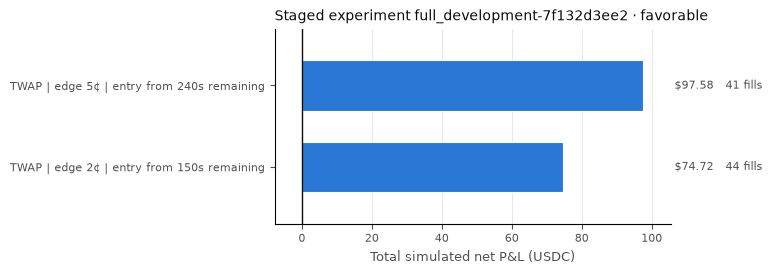

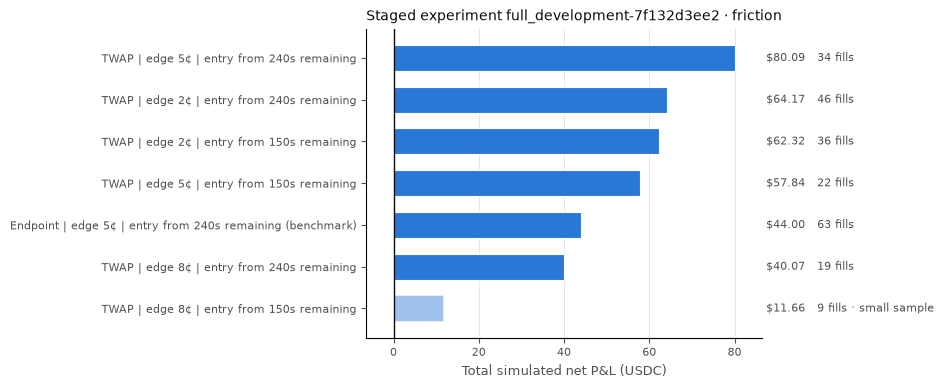

In [18]:
import matplotlib.pyplot as plt

dataset = None
if EXPLORE is None:
    print('Nothing to explore yet: launch a stage first.')
else:
    try:
        dataset = ex.load_experiment(st.STAGED / EXPLORE)
    except FileNotFoundError as exc:
        print(exc)
if dataset is not None:
    display(HTML(ex.scope_html(dataset)))
    for scenario in dataset.scenarios:
        ex.plot_comparison(ex.comparison(dataset, scenario), 'net_pnl',
                           title=f'{dataset.spec.title} · {scenario}')
        plt.show()

**Timelines for a stage run without them (optional, explicit).** The probability-vs-book chart needs each run's per-second timeline. A stage launched with `KEEP_TIMELINES = False` has none, so this cell rebuilds them for **one configuration × one scenario** across all its windows:

* each run is replayed with its saved settings, data and scenario, then checked against the saved run's decision digest;
* results go to the diagnostic cache; the stage's summaries and P&L are untouched;
* about 7–10 min for 45 windows with 4 workers (~2.5 GB RAM each);
* windows that already have a timeline are skipped, so an interrupted run continues where it stopped.

Set `TIMELINES_FOR` to a configuration label and the scenario, then run the cell.

In [19]:
TIMELINES_FOR = None   # e.g. ('TWAP | edge 2¢ | entry from 150s remaining', 'friction')
if TIMELINES_FOR and dataset is not None:
    from tyrex_pm.research.strategy_lab import timelines
    _label, _scenario = TIMELINES_FOR
    _cid = dataset.configs.loc[dataset.configs['label'] == _label, 'config_id'].iloc[0]
    _report = timelines.generate_many(dataset, ex.windows_for(dataset, _cid, _scenario),
                                      workers=WORKERS)
    display(_report['result'].value_counts().to_frame())
else:
    print('No timeline generation requested: nothing was replayed.')

No timeline generation requested: nothing was replayed.


**Interactive explorer** (needs a running kernel and `ipywidgets`). Pick the experiment in the *Dataset* list. Staged experiments appear there automatically, next to the two older datasets.

In [20]:
if dataset is not None:
    try:
        import ipywidgets
    except ImportError:
        print('Static charts are ready. The interactive explorer '
              'requires ipywidgets in this kernel.')
    else:
        app = ex.Explorer(dataset=dataset.spec.key, scenario='friction')
        app.w_config.value = '3b6dbbf4edbdd6d3ac771ecb964342286c391b6fa30bb6e3822b6e54d8805618'
        display(app.view)
else:
    print('No completed stage to explore.')

Static charts are ready. The interactive explorer requires ipywidgets in this kernel.


## Frozen provisional v2 baseline

A/B/C are complete for **full_development-7f132d3ee2**, with 94 development windows.

Provisional default: **TWAP, edge 2 cents/share, entry with 30–150 seconds remaining**, one attempt, hold to resolution. Retry, early exits and re-entry are absent from this v2 baseline. The raw-P&L leader, 5 cents / 240 seconds, is retained as an alternative.

This choice prioritizes less concentrated development performance to close the workflow. Detailed KPI optimization and untouched evaluation remain later work; this is not a live-ready or proven optimal configuration.

B compares Endpoint under friction; C changes execution assumptions for the two TWAP finalists. Neither is a holdout test. All stages remain disarmed.

Baseline saved; no holdout evaluated and no new replay launched.


,stage,label,scenario,requests,fills,wins,losses,net_pnl,total_debit,largest_win
0,A,TWAP | edge 5¢ | entry from 240s remaining,friction,36,34,26,8,80.09,158.95,46.50
1,A,TWAP | edge 2¢ | entry from 150s remaining,friction,45,36,29,7,62.32,166.38,22.43
2,B,Endpoint | edge 5¢ | entry from 240s remaining,friction,74,63,31,32,44.00,308.59,37.20
3,C,TWAP | edge 5¢ | entry from 240s remaining,favorable,41,41,31,10,97.58,203.95,47.01
4,C,TWAP | edge 2¢ | entry from 150s remaining,favorable,44,44,35,9,74.72,217.86,22.70


,value,provenance
setting,,
settlement.functional_id,reference_at_close_vs_open,
settlement.comparison,AT_OR_ABOVE_K,ASSUMED tie rule: UP wins at or above K
settlement.reference_series,chainlink:btcusd:twap:60,"ASSUMED: replayed PolyBolt TWAP feed, not the live RTDS stream"
settlement.reference_units,USD,
settlement.timestamp_meaning,provider_source_time,
settlement.provenance_status,ASSUMED,ASSUMED (not VERIFIED)
settlement.evidence,[],
model.backend,twap_proxy_diffusion,
model.averaging_window_s,60.0,ASSUMED from provider metadata twapLookbackSeconds = 60; boundary and weights unverified


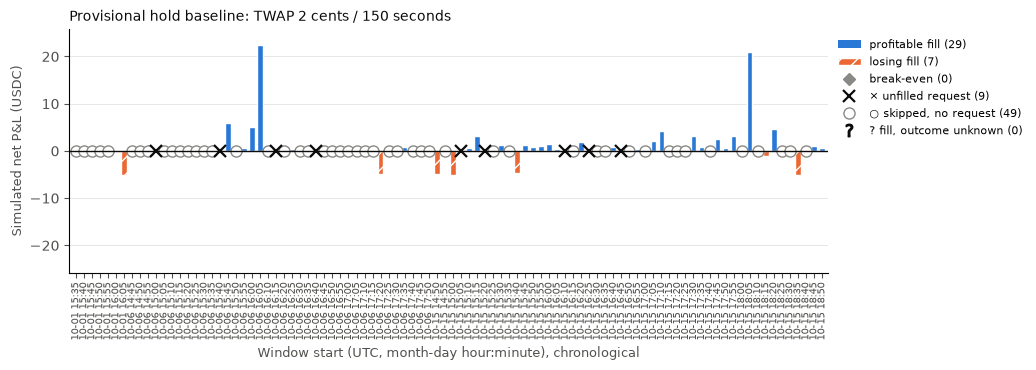

In [21]:
import json
from pathlib import Path

BASELINE_PARAMETERS = json.loads(
    (st.REPO / 'config/research/settlement_value_hold_baseline_v2.json')
    .read_text(encoding='utf-8')
)
_review = json.loads((exp.path / 'baseline_review/analysis.json')
                     .read_text(encoding='utf-8'))
_chosen = {
    '3b6dbbf4edbdd6d3ac771ecb964342286c391b6fa30bb6e3822b6e54d8805618',
    '23ca8d880ec1345c0aa13831d50823affe3253de8ca6b29379f7835ff4143975',
}
_rows = [{k: r[k] for k in
          ('stage', 'label', 'scenario', 'requests', 'fills', 'wins',
           'losses', 'net_pnl', 'total_debit', 'largest_win')}
         for r in _review['comparisons']
         if r['config_id'] in _chosen or r['stage'] == 'B']
display(pd.DataFrame(_rows).round(2))
display(st.flat(BASELINE_PARAMETERS))
_baseline_windows = ex.windows_for(
    dataset, '3b6dbbf4edbdd6d3ac771ecb964342286c391b6fa30bb6e3822b6e54d8805618', 'friction')
ex.plot_windows(_baseline_windows,
                title='Provisional hold baseline: TWAP 2 cents / 150 seconds')
plt.show()
print('Baseline saved; no holdout evaluated and no new replay launched.')

## What these results can and cannot show

* **Can:** how the six entry settings compare *on these development windows* under `friction`; how the TWAP model's entries compare with the Endpoint benchmark's; and how much the execution assumptions alone move a finalist.
* **Cannot:**
  * show validated profitability;
  * replace a probability-quality check (notebook 02);
  * stand in for a holdout evaluation.

  Proxy labels, the provisional K, uncalibrated execution, assumed fees and averaging, readiness/book gaps and the small number of recording dates all limit the conclusions.
* **Next, outside this notebook:**
  * record longer;
  * fix a shortlist from development data only;
  * evaluate it **once** on the holdout with `s2_experiments holdout --configs shortlist.json`.

  This notebook never touches the holdout.